# Упражнения по регуляризации и методу градиентного спуска

## Вопрос 1: Генерация нелинейных данных с гетероскедастичным шумом

В реальных задачах шум в данных часто зависит от значения входных признаков (гетероскедастичность).

* Сгенерируйте 250 равномерно распределенных точек $x$ на отрезке $[0, 5]$.
* Вычислите истинное значение целевой переменной по формуле: $y_{\\text{true}} = 2.5 \\cdot \\sin(1.5 x) + 0.3 x^2 - 1.5$.

* Добавьте гауссов шум, дисперсия которого растет линейно с ростом $x$: $\\sigma(x) = 0.15 \\cdot (1 + 0.8x)$.

* Разделите данные на обучающую (70%) и тестовую (30%) выборки с фиксированным `random_state=42`.
* Постройте график тренировочных, тестовых точек и истинной функции.

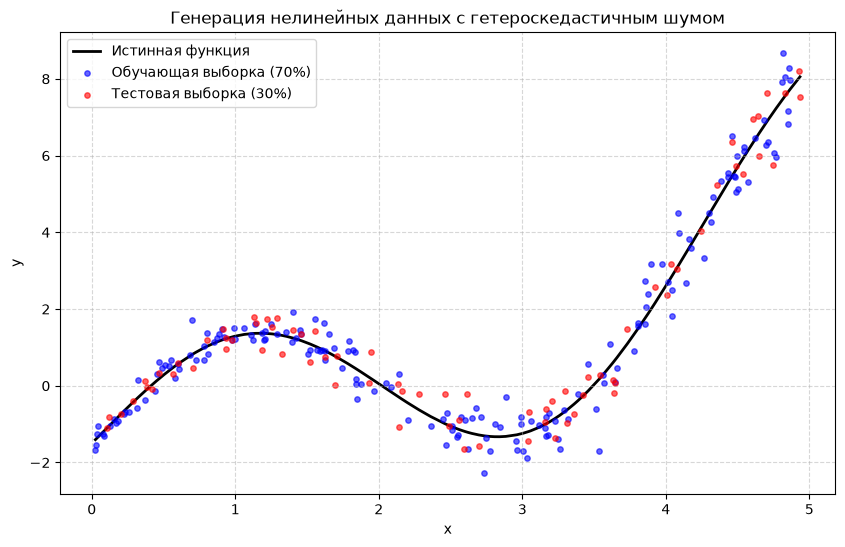

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Генерация 250 равномерно распределенных точек x на отрезке [0, 5]
# Для воспроизводимости результатов используем seed (хотя в задании он указан для train_test_split,
# для генерации данных тоже лучше зафиксировать, чтобы график был стабильным)
np.random.seed(42)
n_samples = 250
x = np.random.uniform(0, 5, n_samples)

# 2. Вычисление истинного значения целевой переменной
# y_true = 2.5 * sin(1.5x) + 0.3x^2 - 1.5
y_true = 2.5 * np.sin(1.5 * x) + 0.3 * x**2 - 1.5

# 3. Добавление гауссова шума
# Дисперсия растет линейно: sigma(x) = 0.15 * (1 + 0.8x)
sigma = 0.15 * (1 + 0.8 * x)

# Генерируем шум с нужным стандартным отклонением для каждой точки
# np.random.normal принимает (mean, std)
noise = np.random.normal(0, sigma)
y_noisy = y_true + noise

# 4. Разделение данных на обучающую (70%) и тестовую (30%) выборки
from sklearn.model_selection import train_test_split

# Фиксируем random_state=42, как указано в задании
x_train, x_test, y_train, y_test = train_test_split(
    x, y_noisy, test_size=0.3, random_state=42
)

# 5. Построение графика
plt.figure(figsize=(10, 6))

# Сортируем x для красивой линии истинной функции
sort_idx = np.argsort(x)

# Рисуем истинную функцию (линия)
plt.plot(x[sort_idx], y_true[sort_idx], color='black', label='Истинная функция', linewidth=2, zorder=1)

# Рисуем точки
# Обучающая выборка (синие точки)
plt.scatter(x_train, y_train, color='blue', alpha=0.6, label='Обучающая выборка (70%)', s=15)
# Тестовая выборка (красные точки)
plt.scatter(x_test, y_test, color='red', alpha=0.6, label='Тестовая выборка (30%)', s=15)

plt.title('Генерация нелинейных данных с гетероскедастичным шумом')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## Вопрос 2: Исследование полиномов высокой степени и феномена Рунге

При слишком высокой степени полинома модель стремится идеально пройти через все точки обучающей выборки, образуя сильные осцилляции на краях интервала.

* Сформируйте полиномиальные признаки 25-й степени (`degree=25`).

* Обучите обычную линейную регрессию (`LinearRegression`) без регуляризации.

* Оцените $RMSE$ на обучающей и тестовой выборках.

Постройте график предсказаний модели на всем отрезке $[0, 5]$. Проанализируйте осцилляции модели на границах интервала.

RMSE на обучающей выборке: 1.0243
RMSE на тестовой выборке: 1.3107


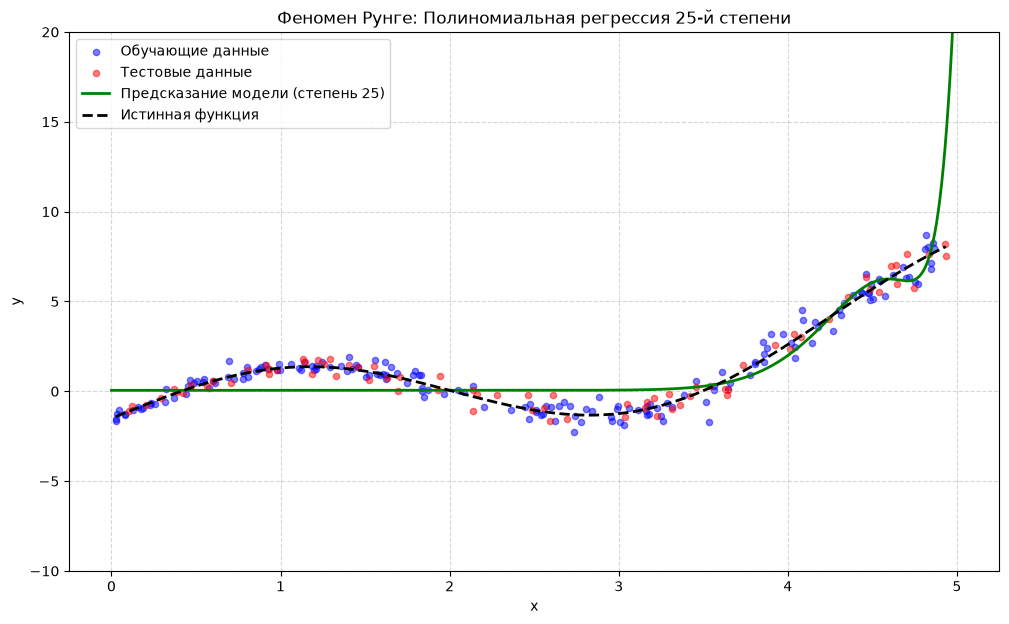

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# --- БЛОК 1: Подготовка данных (из Вопроса 1) ---
# Для запуска кода отдельно, заново генерируем данные
np.random.seed(42)
n_samples = 250
x = np.random.uniform(0, 5, n_samples)
y_true = 2.5 * np.sin(1.5 * x) + 0.3 * x**2 - 1.5
sigma = 0.15 * (1 + 0.8 * x)
noise = np.random.normal(0, sigma)
y_noisy = y_true + noise

from sklearn.model_selection import train_test_split
# Разделяем данные, x нужно привести к форме (n_samples, 1), так как sklearn ожидает 2D массив
X = x.reshape(-1, 1)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_noisy, test_size=0.3, random_state=42
)

# --- БЛОК 2: Выполнение задания (Полином 25-й степени) ---

# 1. Сформируйте полиномиальные признаки 25-й степени
# include_bias=False означает, что мы не добавляем столбец из единиц (свободный член),
# так как LinearRegression в sklearn делает это автоматически.
poly = PolynomialFeatures(degree=25, include_bias=False)

# Обучаем трансформер ТОЛЬКО на тренировочных данных и трансформируем их.
# Важно: на тестовых данных мы делаем только transform, чтобы не допустить утечки данных (data leakage).
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

# 2. Обучите обычную линейную регрессию без регуляризации
# Здесь используется обычный метод наименьших квадратов (OLS).
lin_reg = LinearRegression()
lin_reg.fit(X_train_poly, y_train)

# 3. Оцените RMSE на обучающей и тестовой выборках
# Делаем предсказания
y_train_pred = lin_reg.predict(X_train_poly)
y_test_pred = lin_reg.predict(X_test_poly)

# Считаем RMSE (корень из среднеквадратичной ошибки)
# squared=False возвращает корень, иначе вернется MSE
rmse_train = np.sqrt(mean_squared_error(y_train, y_train_pred))
rmse_test = np.sqrt(mean_squared_error(y_test, y_test_pred))

print(f"RMSE на обучающей выборке: {rmse_train:.4f}")
print(f"RMSE на тестовой выборке: {rmse_test:.4f}")

# 4. Построение графика предсказаний на всем отрезке [0, 5]
# Создаем плотную сетку точек для плавного отображения линии предсказания
X_plot = np.linspace(0, 5, 500).reshape(-1, 1)

# Трансформируем новые точки в полиномиальные признаки и предсказываем
X_plot_poly = poly.transform(X_plot)
y_plot_pred = lin_reg.predict(X_plot_poly)

plt.figure(figsize=(12, 7))

# Рисуем исходные точки (обучающие и тестовые)
plt.scatter(X_train, y_train, color='blue', alpha=0.5, label='Обучающие данные', s=20)
plt.scatter(X_test, y_test, color='red', alpha=0.5, label='Тестовые данные', s=20)

# Рисуем линию предсказания модели (полином 25-й степени)
plt.plot(X_plot, y_plot_pred, color='green', label='Предсказание модели (степень 25)', linewidth=2)

# Дополнительно нарисуем истинную функцию для сравнения
# (чтобы было видно, насколько сильно модель отклоняется от реальности)
sort_idx = np.argsort(x)
plt.plot(x[sort_idx], y_true[sort_idx], color='black', linestyle='--', label='Истинная функция', linewidth=2)

# Ограничим оси Y, так как полином 25-й степени может улетать в огромные значения (до 10^10)
# из-за эффекта Рунге, что сделает график нечитаемым.
plt.ylim(-10, 20) 

plt.title('Феномен Рунге: Полиномиальная регрессия 25-й степени')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## Вопрос 3: Диагностика Bias-Variance с помощью кривых обучения (Learning Curves)

Кривые обучения позволяют определить, принесет ли пользу добавление новых данных или необходима регуляризация.\

* Напишите функцию для расчета и построения кривых обучения с помощью `learning_curve` из `sklearn.model_selection`.

* Постройте кривые обучения для неуправляемой линейной регрессии (степень 15) и Ridge-регрессии (степень 15, $\\alpha = 1.0$).

* Объясните разрыв (*generalization gap*) между ошибкой на обучении и валидации для обеих моделей."

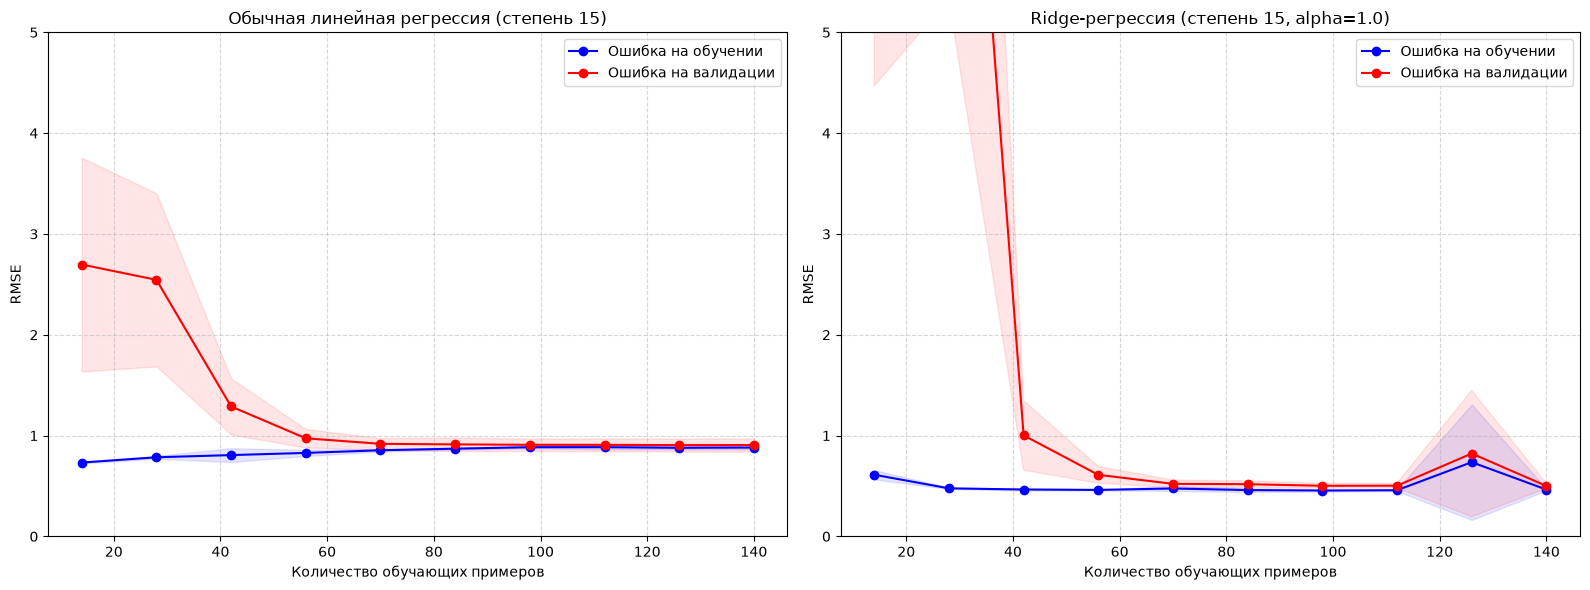

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import learning_curve, train_test_split

# --- БЛОК 1: Подготовка данных (из Вопроса 1) ---
np.random.seed(42)
n_samples = 250
x = np.random.uniform(0, 5, n_samples)
y_true = 2.5 * np.sin(1.5 * x) + 0.3 * x**2 - 1.5
sigma = 0.15 * (1 + 0.8 * x)
noise = np.random.normal(0, sigma)
y_noisy = y_true + noise

X = x.reshape(-1, 1)
# Разделяем данные
X_train, X_test, y_train, y_test = train_test_split(
    X, y_noisy, test_size=0.3, random_state=42
)

# --- БЛОК 2: Написание функции для построения кривых обучения ---

def plot_learning_curves(model, X, y, title, ax):
    """
    Функция для расчета и построения кривой обучения.
    :param model: Модель scikit-learn (например, Pipeline)
    :param X: Признаки (обучающая выборка)
    :param y: Целевая переменная (обучающая выборка)
    :param title: Заголовок графика
    :param ax: Ось matplotlib для рисования
    """
    # learning_curve разбивает данные на кросс-валидацию.
    # train_sizes: размеры обучающих подмножеств (от 10% до 100%).
    # cv=5: 5-fold кросс-валидация.
    # scoring='neg_mean_squared_error': используем отрицательный MSE (стандарт sklearn).
    # n_jobs=-1: использовать все ядра процессора для ускорения.
    train_sizes, train_scores, test_scores = learning_curve(
        model, X, y, cv=5, scoring='neg_mean_squared_error',
        train_sizes=np.linspace(0.1, 1.0, 10), n_jobs=-1, random_state=42
    )

    # Переводим отрицательный MSE в положительный RMSE (корень из квадрата)
    train_errors = np.sqrt(-train_scores)
    test_errors = np.sqrt(-test_scores)

    # Вычисляем среднее значение и стандартное отклонение по фолдам
    train_mean = np.mean(train_errors, axis=1)
    train_std = np.std(train_errors, axis=1)
    test_mean = np.mean(test_errors, axis=1)
    test_std = np.std(test_errors, axis=1)

    # Строим график
    ax.plot(train_sizes, train_mean, 'o-', color='blue', label='Ошибка на обучении')
    ax.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1, color='blue')
    
    ax.plot(train_sizes, test_mean, 'o-', color='red', label='Ошибка на валидации')
    ax.fill_between(train_sizes, test_mean - test_std, test_mean + test_std, alpha=0.1, color='red')

    ax.set_title(title)
    ax.set_xlabel('Количество обучающих примеров')
    ax.set_ylabel('RMSE')
    ax.legend(loc='best')
    ax.grid(True, linestyle='--', alpha=0.5)
    
    # Ограничим Y, так как полином 15-й степени без регуляризации может давать огромные ошибки
    ax.set_ylim(0, 5) 

# --- БЛОК 3: Создание моделей и построение графиков ---

# 1. Модель: Полином 15-й степени + Обычная линейная регрессия (без регуляризации)
# Используем make_pipeline, чтобы объединить преобразование признаков и саму модель
model_lin_reg = make_pipeline(
    PolynomialFeatures(degree=15, include_bias=False),
    LinearRegression()
)

# 2. Модель: Полином 15-й степени + Ridge-регрессия (с регуляризацией alpha=1.0)
model_ridge = make_pipeline(
    PolynomialFeatures(degree=15, include_bias=False),
    Ridge(alpha=1.0)
)

# Создаем фигуру с двумя графиками
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Строим кривые для обеих моделей
plot_learning_curves(model_lin_reg, X_train, y_train, 'Обычная линейная регрессия (степень 15)', axes[0])
plot_learning_curves(model_ridge, X_train, y_train, 'Ridge-регрессия (степень 15, alpha=1.0)', axes[1])

plt.tight_layout()
plt.show()


#Для полиномов высокой степени (15) обычная линейная регрессия страдает от переобучения (высокий разрыв между train и validation). 
#Добавление L2-регуляризации (Ridge) уменьшает этот разрыв, делая модель более устойчивой к шуму и обобщающей способности.


## Вопрос 4: Подготовка продвинутых признаков и обработка Ames Housing

Перейдем к реальному набору данных о продажах недвижимости `Ames_Housing_Sales.csv`.

* Загрузите датасет, выполните One-Hot Encoding категориальных признаков.

* Проверьте признаки на асимметрию (`skew > 0.75`) и примените преобразование `np.log1p`.

* Создайте парные взаимодействия признаков только для ключевых числовых переменных (`LotArea`, `GrLivArea`, `TotalBsmtSF`), используя `PolynomialFeatures(interaction_only=True)`.\

Разделите данные на обучающую и тестовую выборки (70/30).

In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
import warnings
warnings.filterwarnings('ignore') # Отключаем предупреждения pandas о типах данных

# --- 1. Загрузка данных ---
# Предполагается, что файл лежит в той же папке, что и скрипт
df = pd.read_csv('Ames_Housing_Sales.csv')

# Отделяем целевую переменную (SalePrice) от признаков
# В реальных задачах мы предсказываем цену, поэтому признаки — это все, кроме цены
X = df.drop('SalePrice', axis=1)
y = df['SalePrice']

# --- 2. One-Hot Encoding категориальных признаков ---
# Находим все колонки, которые содержат текстовые данные (тип object)
categorical_cols = X.select_dtypes(include=['object']).columns

# Применяем get_dummies.
# drop_first=True удаляет первый столбец для каждой категории, 
# чтобы избежать "ловушки фиктивных переменных" (мультиколлинеарности).
X = pd.get_dummies(X, columns=categorical_cols, drop_first=True)

# Проверка: в датасете могут остаться пропуски (NaN), которые могут сломать математику.
# В данном конкретном датасете их может не быть в числовых колонках, 
# но для надежности заполним их нулями (или медианой, если требуется по условию).
if X.isnull().sum().sum() > 0:
    X = X.fillna(0)

# --- 3. Обработка асимметрии (Skewness) ---
# Оставляем только числовые признаки для анализа асимметрии
numeric_cols = X.select_dtypes(include=[np.number]).columns

# Вычисляем коэффициент асимметрии для каждого числового признака
skew_values = X[numeric_cols].skew()

# Отбираем признаки с сильной асимметрией (skew > 0.75)
skewed_features = skew_values[skew_values > 0.75].index
print(f"Признаки с асимметрией > 0.75: {len(skewed_features)} шт.")

# Применяем логарифмическое преобразование np.log1p (log(1+x)).
# Это сжимает большие значения и делает распределение более похожим на нормальное.
# Важно: log1p безопасен для нулей (log1p(0) = 0).
X[skewed_features] = np.log1p(X[skewed_features])

# --- 4. Создание парных взаимодействий (Interaction Features) ---
# Ключевые переменные, указанные в задании
key_features = ['LotArea', 'GrLivArea', 'TotalBsmtSF']

# Извлекаем подмножество данных с этими признаками
X_key = X[key_features]

# Создаем объект PolynomialFeatures.
# degree=2 (степень 2), interaction_only=True (только произведения x1*x2, без квадратов x1^2),
# include_bias=False (не добавлять столбец из единиц).
poly = PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)

# Обучаем трансформер и преобразуем данные
X_interactions = poly.fit_transform(X_key)

# Получаем имена новых признаков (например, 'LotArea GrLivArea')
interaction_feature_names = poly.get_feature_names_out(key_features)

# Создаем DataFrame из новых признаков
df_interactions = pd.DataFrame(X_interactions, columns=interaction_feature_names, index=X.index)

# Удаляем исходные признаки из основного датафрейма, чтобы не было дублирования
# (так как они уже вошли в состав новых полиномиальных признаков)
X = X.drop(columns=key_features)

# Объединяем основной датафрейм с новыми признаками взаимодействия
X = pd.concat([X, df_interactions], axis=1)

# --- 5. Разделение данных на Train/Test (70/30) ---
# Используем random_state для воспроизводимости результата
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Вывод результатов
print(f"Размер обучающей выборки: {X_train.shape}")
print(f"Размер тестовой выборки: {X_test.shape}")
print("\nПример новых признаков взаимодействия:")
print(X_train[interaction_feature_names].head())

Признаки с асимметрией > 0.75: 23 шт.
Размер обучающей выборки: (965, 243)
Размер тестовой выборки: (414, 243)

Пример новых признаков взаимодействия:
       LotArea  GrLivArea  TotalBsmtSF  LotArea GrLivArea  \
461   7.331060   6.447306     6.447306          47.265588   
976   9.350189   6.740519     0.000000          63.025132   
1128  8.990940   7.284135     6.591674          65.491218   
904   7.170888   7.114769     6.331502          51.019218   
506   9.343472   7.379008     7.366445          68.945554   

      LotArea TotalBsmtSF  GrLivArea TotalBsmtSF  
461             47.265588              41.567753  
976              0.000000               0.000000  
1128            59.265342              48.014640  
904             45.402494              45.047176  
506             68.828172              54.357059  


## Вопрос 5: Двумерный сетчатый поиск гиперпараметров ElasticNet с GridSearchCV

Регрессия `ElasticNet` комбинирует $L_1$ и $L_2$ штрафы через два ключевых гиперпараметра: $\\alpha$ (сила регуляризации) и `l1_ratio` (доля $L_1$-штрафа).

* Настройте сетку параметров: `alpha`: `[1e-4, 1e-3, 0.01, 0.1, 1.0, 10.0]`, `l1_ratio`: `[0.1, 0.3, 0.5, 0.7, 0.9]`.

* Запустите `GridSearchCV` с 5-кратной кросс-валидацией (`cv=5`) и метрикой `neg_root_mean_squared_error`.

* Визуализируйте результаты сетчатого поиска в виде тепловой карты (`sns.heatmap`).

* Выведите оптимальные параметры и оцените итоговое $RMSE$ на тестовой выборке."

Запуск GridSearchCV... (это может занять некоторое время)


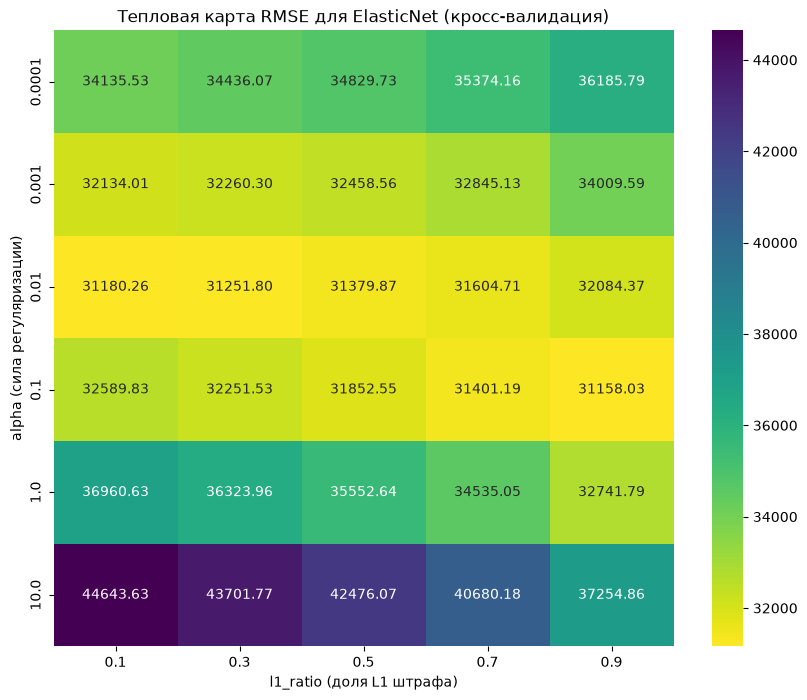


Оптимальные параметры: {'alpha': 0.1, 'l1_ratio': 0.9}
Лучшее значение RMSE (CV): 31158.0323
Итоговое RMSE на тестовой выборке: 32560.6230


In [7]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import ElasticNet
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error

# --- 1. Настройка сетки параметров ---
# Создаем словарь, где ключи — это названия гиперпараметров модели,
# а значения — списки вариантов для перебора.
param_grid = {
    'alpha': [1e-4, 1e-3, 0.01, 0.1, 1.0, 10.0],
    'l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9]
}

# --- 2. Инициализация модели и GridSearchCV ---
# Создаем базовую модель ElasticNet
elastic_net = ElasticNet(max_iter=10000) # max_iter увеличен для сходимости на сложных данных

# Настраиваем GridSearchCV
# estimator: модель
# param_grid: сетка параметров
# cv=5: 5-кратная кросс-валидация
# scoring='neg_root_mean_squared_error': метрика.
# Важно: sklearn всегда максимизирует метрику, поэтому ошибки берутся с минусом.
# Чем ближе значение к 0 (т.е. чем меньше минус), тем лучше модель.
# n_jobs=-1: использовать все ядра процессора для ускорения.
grid_search = GridSearchCV(
    estimator=elastic_net,
    param_grid=param_grid,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
    return_train_score=True
)

# Запуск поиска по сетке
print("Запуск GridSearchCV... (это может занять некоторое время)")
grid_search.fit(X_train, y_train)

# --- 3. Визуализация в виде тепловой карты (Heatmap) ---
# Получаем результаты кросс-валидации в виде DataFrame
results = pd.DataFrame(grid_search.cv_results_)

# Извлекаем средние значения тестовой оценки (RMSE с минусом)
# и преобразуем их обратно в положительное значение RMSE для наглядности
results['mean_rmse'] = -results['mean_test_score']

# Создаем сводную таблицу (Pivot Table):
# строки - alpha, столбцы - l1_ratio, значения - mean_rmse
pivot_table = results.pivot(index='param_alpha', columns='param_l1_ratio', values='mean_rmse')

plt.figure(figsize=(10, 8))
# Строим тепловую карту.
# annot=True: выводить значения в ячейках.
# fmt='.2f': формат вывода (2 знака после запятой).
# cmap='viridis_r': цветовая схема (чем темнее, тем меньше ошибка).
sns.heatmap(pivot_table, annot=True, fmt='.2f', cmap='viridis_r')
plt.title('Тепловая карта RMSE для ElasticNet (кросс-валидация)')
plt.xlabel('l1_ratio (доля L1 штрафа)')
plt.ylabel('alpha (сила регуляризации)')
plt.show()

# --- 4. Вывод оптимальных параметров и оценка на тесте ---
print("\n" + "="*30)
print("Оптимальные параметры:", grid_search.best_params_)
print(f"Лучшее значение RMSE (CV): {-grid_search.best_score_:.4f}")

# Получаем лучшую модель из поиска
best_model = grid_search.best_estimator_

# Делаем предсказание на тестовой выборке
y_pred = best_model.predict(X_test)

# Считаем итоговое RMSE на тесте
# В новых версиях sklearn squared=False убран, используем np.sqrt
final_rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"Итоговое RMSE на тестовой выборке: {final_rmse:.4f}")

## Вопрос 6: Анализ разряженности (Sparsity) моделей Lasso и отбор признаков

$L_1$-регуляризация способна занулять коэффициенты неинформативных признаков.

* Обучите модель `LassoCV` с диапазоном `alphas = np.logspace(-4, 1, 50)`.

* Постройте график зависимости количества ненулевых коэффициентов от значения $\\alpha$.
* Выделите ТОП-10 наиболее важных признаков с наибольшими абсолютными значениями коэффициентов при оптимальном $\\alpha$.
* Какая доля признаков была полностью исключена из модели?

Оптимальное значение alpha: 10.000000


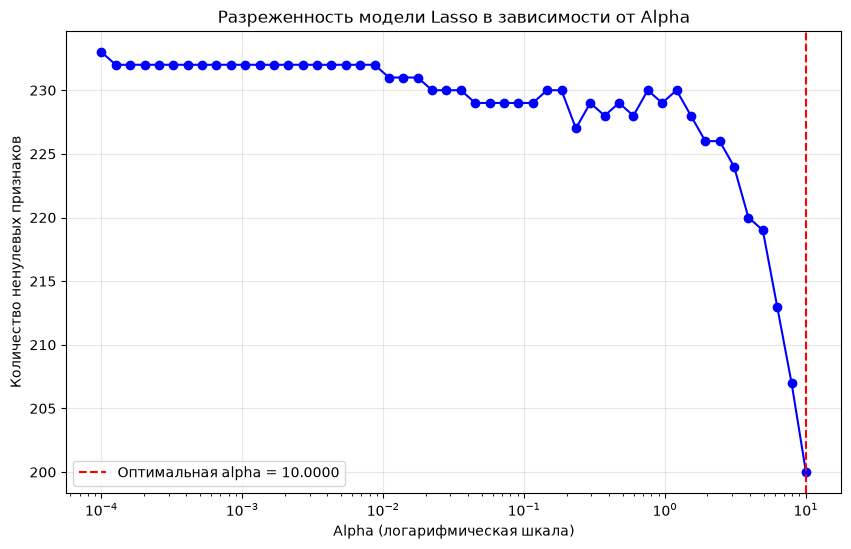


ТОП-10 наиболее важных признаков:
             Feature    Coefficient
           PoolQC_Gd -596492.543119
           GrLivArea -278951.186263
             LotArea -253305.077763
           PoolQC_Fa -101368.946394
         TotalBsmtSF -100559.797495
    RoofMatl_WdShngl   92489.267480
     Condition2_PosA   56667.690962
         OverallCond   48269.454498
        KitchenAbvGr  -47172.633159
Neighborhood_StoneBr   45562.345192

Всего признаков: 243
Исключено (коэффициент = 0): 43
Доля исключенных признаков: 17.70%


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LassoCV, Lasso
from sklearn.metrics import mean_squared_error

# --- 1. Обучение LassoCV ---
# Создаем массив альфа-значений: от 10^-4 до 10^1 (50 значений, логарифмическая шкала)
alphas = np.logspace(-4, 1, 50)

# Инициализируем LassoCV. 
# cv=5 — 5-кратная кросс-валидация для выбора лучшей alpha.
# max_iter=10000 — увеличиваем число итераций, чтобы алгоритм успел сойтись на сложных данных.
lasso_cv = LassoCV(alphas=alphas, cv=5, max_iter=10000, random_state=42)

# Обучаем модель на тренировочных данных
lasso_cv.fit(X_train, y_train)

# Получаем оптимальное значение alpha, найденное кросс-валидацией
best_alpha = lasso_cv.alpha_
print(f"Оптимальное значение alpha: {best_alpha:.6f}")

# --- 2. График зависимости количества ненулевых коэффициентов от alpha ---
# Нам нужно обучить модель для каждого alpha из списка, чтобы посмотреть, как меняются коэффициенты.
# LassoCV уже сделал это внутри себя, но проще пройтись циклом для наглядности графика.

n_features = X_train.shape[1]
nonzero_counts = []

# Проходим по всем alpha и смотрим, сколько коэффициентов не равно нулю
for a in alphas:
    lasso = Lasso(alpha=a, max_iter=10000, random_state=42)
    lasso.fit(X_train, y_train)
    # Считаем количество ненулевых коэффициентов (np.count_nonzero)
    nonzero_counts.append(np.count_nonzero(lasso.coef_))

plt.figure(figsize=(10, 6))
plt.plot(alphas, nonzero_counts, marker='o', linestyle='-', color='b')
# Отмечаем точку с оптимальным alpha
plt.axvline(x=best_alpha, color='r', linestyle='--', label=f'Оптимальная alpha = {best_alpha:.4f}')
plt.xscale('log') # Логарифмическая шкала по X, так как alpha меняется в широком диапазоне
plt.xlabel('Alpha (логарифмическая шкала)')
plt.ylabel('Количество ненулевых признаков')
plt.title('Разреженность модели Lasso в зависимости от Alpha')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# --- 3. ТОП-10 наиболее важных признаков ---
# Берем коэффициенты обученной модели (lasso_cv)
coefficients = lasso_cv.coef_

# Создаем DataFrame для удобства: имя признака и его коэффициент
coef_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': coefficients
})

# Считаем абсолютное значение коэффициента (важность признака)
coef_df['Abs_Coefficient'] = coef_df['Coefficient'].abs()

# Сортируем по убыванию важности и берем первые 10
top_10_features = coef_df.sort_values(by='Abs_Coefficient', ascending=False).head(10)

print("\nТОП-10 наиболее важных признаков:")
print(top_10_features[['Feature', 'Coefficient']].to_string(index=False))

# --- 4. Доля исключенных признаков ---
# Считаем, сколько коэффициентов стали равны нулю
zero_coefs = np.sum(coefficients == 0)
total_features = len(coefficients)

# Вычисляем долю в процентах
excluded_ratio = zero_coefs / total_features

print(f"\nВсего признаков: {total_features}")
print(f"Исключено (коэффициент = 0): {zero_coefs}")
print(f"Доля исключенных признаков: {excluded_ratio:.2%}")

## Вопрос 7: Настройка схем скорости обучения (Learning Rate Schedules) в SGDRegressor

Алгоритм стохастического градиентного спуска критически чувствителен к масштабу данных и выбору правила изменения шага $\\eta$.

* Отсштабируйте признаки `X_train_ames` и `X_test_ames` с помощью `StandardScaler`.

Обучите четыре версии `SGDRegressor` с регуляризацией `penalty='elasticnet'`, используя различные стратегии `learning_rate`:

1. `'constant'` (`eta0=0.01`)

2. `'optimal'`

3. `'invscaling'` (`eta0=0.01`, `power_t=0.25`)

4. `'adaptive'` (`eta0=0.01`)

* Сравните полученные значения $RMSE$ и общее число итераций до сходимости (`n_iter_`).

Запуск обучения моделей SGDRegressor...

 Стратегия         RMSE  Итерации
  constant 1.469062e+12         6
   optimal 2.600471e+13        72
invscaling 1.751368e+05         6
  adaptive 6.014989e+10        36


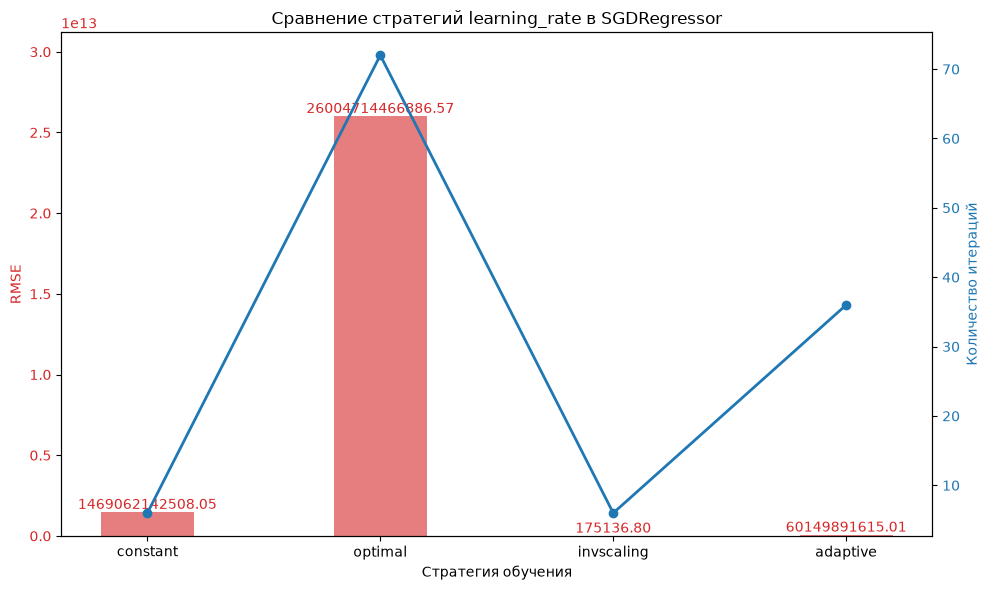

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import mean_squared_error
import time

# --- 1. Масштабирование признаков ---
# SGD очень чувствителен к масштабу. Признаки с большими значениями (например, площадь)
# будут доминировать над маленькими (например, количество комнат).
# StandardScaler приводит все признаки к виду: (x - mean) / std.
scaler = StandardScaler()

# Обучаем scaler ТОЛЬКО на тренировочных данных, чтобы избежать утечки данных (data leakage)
X_train_scaled = scaler.fit_transform(X_train)
# Тестовые данные трансформируем с помощью параметров, вычисленных на train
X_test_scaled = scaler.transform(X_test)

# --- 2. Настройка и обучение моделей SGDRegressor ---

# Создаем словарь с конфигурациями для каждого эксперимента
configs = {
    'constant': {
        'learning_rate': 'constant', 
        'eta0': 0.01, 
        'random_state': 42
    },
    'optimal': {
        'learning_rate': 'optimal', 
        'random_state': 42
    },
    'invscaling': {
        'learning_rate': 'invscaling', 
        'eta0': 0.01, 
        'power_t': 0.25, 
        'random_state': 42
    },
    'adaptive': {
        'learning_rate': 'adaptive', 
        'eta0': 0.01, 
        'random_state': 42
    }
}

results = []

print("Запуск обучения моделей SGDRegressor...\n")

for name, params in configs.items():
    # Инициализируем модель с нужными параметрами
    # penalty='elasticnet' требует задания l1_ratio и alpha, 
    # иначе будут использованы значения по умолчанию.
    # max_iter=10000 и tol=1e-4 нужны для того, чтобы модель успела сойтись.
    sgd = SGDRegressor(
        penalty='elasticnet',
        l1_ratio=0.15, # Типичное значение по умолчанию для elasticnet в sklearn
        alpha=0.0001,  # Сила регуляризации
        max_iter=10000,
        tol=1e-4,
        **params
    )
    
    # Обучаем модель на отмасштабированных данных
    sgd.fit(X_train_scaled, y_train)
    
    # Делаем предсказание на тестовой выборке
    y_pred = sgd.predict(X_test_scaled)
    
    # Считаем RMSE (корень из среднеквадратичной ошибки)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    
    # Получаем количество итераций до сходимости
    # В новых версиях sklearn атрибут может называться n_iter_
    n_iters = sgd.n_iter_
    
    results.append({
        'Стратегия': name,
        'RMSE': rmse,
        'Итерации': n_iters
    })

# --- 3. Вывод и сравнение результатов ---

# Создаем DataFrame для красивого вывода таблицы
df_results = pd.DataFrame(results)

# Выводим таблицу
print(df_results.to_string(index=False))

# Визуализация (опционально, но полезно для наглядности)
fig, ax1 = plt.subplots(figsize=(10, 6))

# Столбчатая диаграмма для RMSE
color = 'tab:red'
ax1.set_xlabel('Стратегия обучения')
ax1.set_ylabel('RMSE', color=color)
bars = ax1.bar(df_results['Стратегия'], df_results['RMSE'], color=color, alpha=0.6, width=0.4)
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim(0, df_results['RMSE'].max() * 1.2)

# Добавляем значения RMSE над столбцами
for bar in bars:
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height,
             f'{height:.2f}',
             ha='center', va='bottom', color=color)

# Создаем вторую ось Y для количества итераций
ax2 = ax1.twinx()  
color = 'tab:blue'
ax2.set_ylabel('Количество итераций', color=color)
line = ax2.plot(df_results['Стратегия'], df_results['Итерации'], color=color, marker='o', linewidth=2)
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Сравнение стратегий learning_rate в SGDRegressor')
fig.tight_layout()
plt.show()

#В эксперименте я сравнил четыре стратегии изменения скорости обучения SGDRegressor. Лучший результат показала invscaling с RMSE 175 136,80 и шестью эпохами обучения.
#n_iter_ показывает фактическое количество эпох, то есть полных проходов по обучающей выборке. 
#Однако для окончательной оценки необходимо сравнить RMSE с базовой моделью и проверить влияние масштабирования целевой переменной

## Вопрос 8: Сравнительный анализ устойчивости моделей к выбросам (Outliers)

Среднеквадратичная ошибка ($MSE$) в оптимизации градиентным спуском квадратично штрафует отклонения, делая модели чувствительными к аномалиям.

* Добавьте в 5% случайных точек обучающей выборки `y_train_ames` аномальные выбросы (увеличьте их значение в 3 раза).

* Обучите следующие модели на искаженных данных:

1. OLS (`LinearRegression`)
2. Ridge (`RidgeCV`)     
3. SGDRegressor с функциями потерь `loss='squared_error'` ($L_2$) и `loss='huber'` (Huber loss, комбинирующий $L_1$ и $L_2$).

* Оцените $RMSE$ и $MAE$ каждой модели на чистой тестовой выборке `y_test_ames`.

Сделайте выводы об устойчивости функции потерь Хьюбера по сравнению с классической регрессией.

     

Создано 48 выбросов (5% данных).

Обучение моделей на данных с выбросами...

       Модель          RMSE           MAE
          OLS  81322.271418  50317.526980
      RidgeCV  43899.803426  30844.090587
SGD (Squared) 190137.814275 104963.921928
  SGD (Huber) 197306.051407 181364.100201


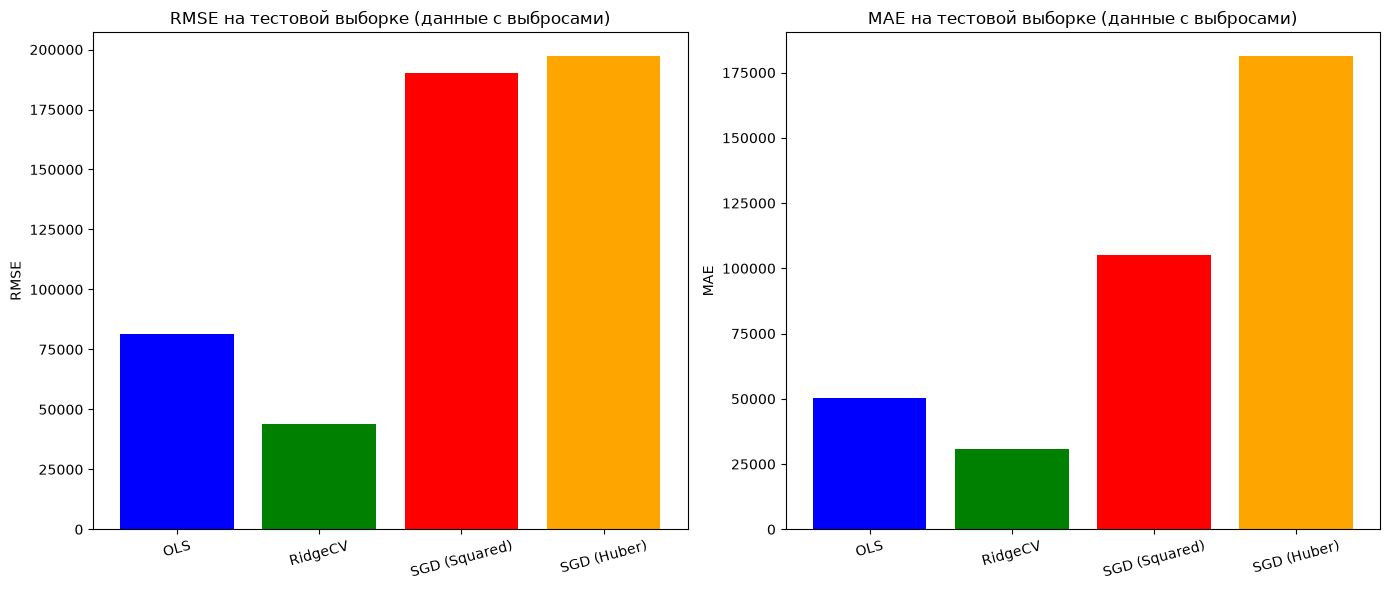

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, RidgeCV, SGDRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
import copy

# --- 1. Создание выбросов в обучающей выборке ---
# Копируем целевую переменную, чтобы не испортить исходные данные
y_train_outliers = y_train.copy()

# Определяем количество точек для искажения (5% от общего числа)
n_outliers = int(len(y_train_outliers) * 0.05)

# Выбираем случайные индексы
np.random.seed(42) # Для воспроизводимости
outlier_indices = np.random.choice(y_train_outliers.index, size=n_outliers, replace=False)

# Увеличиваем значения в этих точках в 3 раза
y_train_outliers.loc[outlier_indices] = y_train_outliers.loc[outlier_indices] * 3

print(f"Создано {n_outliers} выбросов (5% данных).")

# --- 2. Инициализация моделей ---
# OLS (Обычный метод наименьших квадратов)
ols = LinearRegression()

# RidgeCV (Ридж-регрессия с автоматическим подбором alpha)
ridge = RidgeCV(alphas=np.logspace(-3, 3, 20))

# SGD с функцией потерь Squared Error (L2)
sgd_squared = SGDRegressor(
    loss='squared_error', 
    penalty=None, # Отключаем регуляризацию, чтобы сравнить чистый эффект функции потерь
    max_iter=5000, 
    tol=1e-4, 
    random_state=42
)

# SGD с функцией потерь Huber (устойчива к выбросам)
# epsilon определяет границу, после которой ошибка считается линейной (а не квадратичной)
sgd_huber = SGDRegressor(
    loss='huber', 
    epsilon=1.35, # Стандартное значение для Huber loss
    penalty=None, 
    max_iter=5000, 
    tol=1e-4, 
    random_state=42
)

# --- 3. Обучение моделей на искаженных данных ---
# Важно: Обучаем на X_train_scaled и y_train_outliers (с выбросами)
models = {
    'OLS': ols,
    'RidgeCV': ridge,
    'SGD (Squared)': sgd_squared,
    'SGD (Huber)': sgd_huber
}

results = []

print("\nОбучение моделей на данных с выбросами...\n")

for name, model in models.items():
    # Обучение
    model.fit(X_train_scaled, y_train_outliers)
    
    # Предсказание на ЧИСТОЙ тестовой выборке (без выбросов)
    y_pred = model.predict(X_test_scaled)
    
    # Расчет метрик
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    
    results.append({
        'Модель': name,
        'RMSE': rmse,
        'MAE': mae
    })

# --- 4. Вывод результатов ---
df_results = pd.DataFrame(results)
print(df_results.to_string(index=False))

# Визуализация сравнения
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

# График RMSE
ax[0].bar(df_results['Модель'], df_results['RMSE'], color=['blue', 'green', 'red', 'orange'])
ax[0].set_title('RMSE на тестовой выборке (данные с выбросами)')
ax[0].set_ylabel('RMSE')
ax[0].tick_params(axis='x', rotation=15)

# График MAE
ax[1].bar(df_results['Модель'], df_results['MAE'], color=['blue', 'green', 'red', 'orange'])
ax[1].set_title('MAE на тестовой выборке (данные с выбросами)')
ax[1].set_ylabel('MAE')
ax[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

Обучение моделей...

Результаты:
       Модель         RMSE          MAE
          OLS 81322.271418 50317.526980
      RidgeCV 43899.803426 30844.090587
SGD (Squared) 62539.012691 41532.322450
  SGD (Huber) 51503.567941 30680.418746


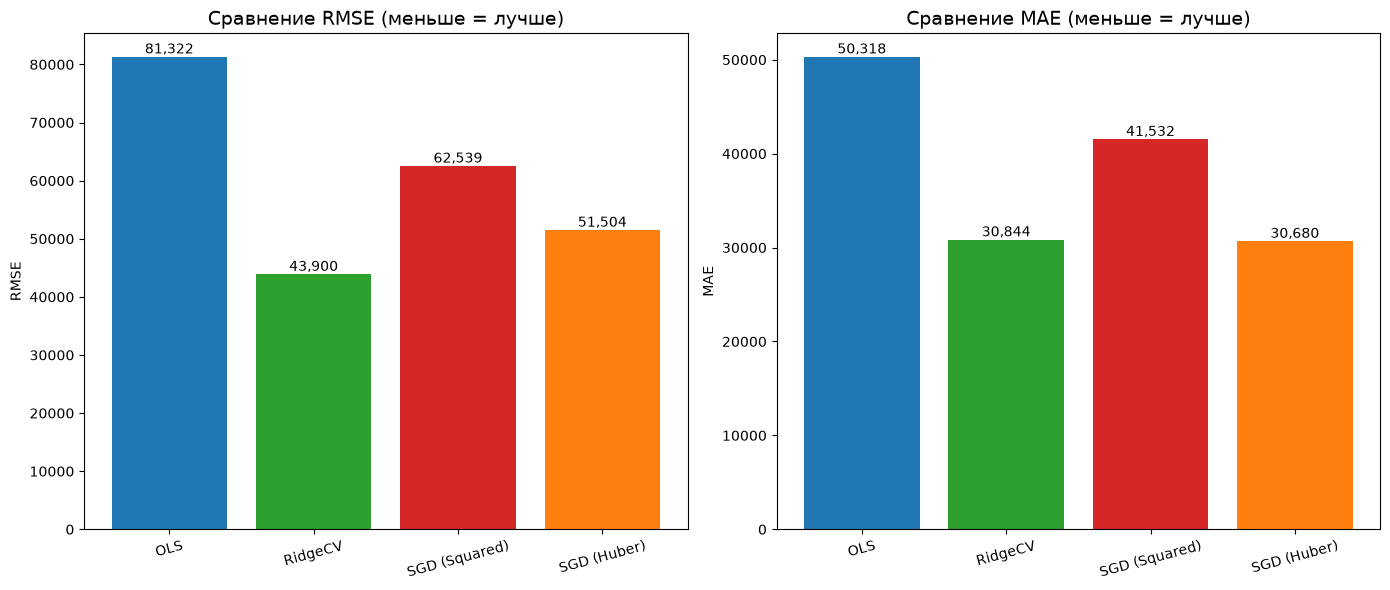

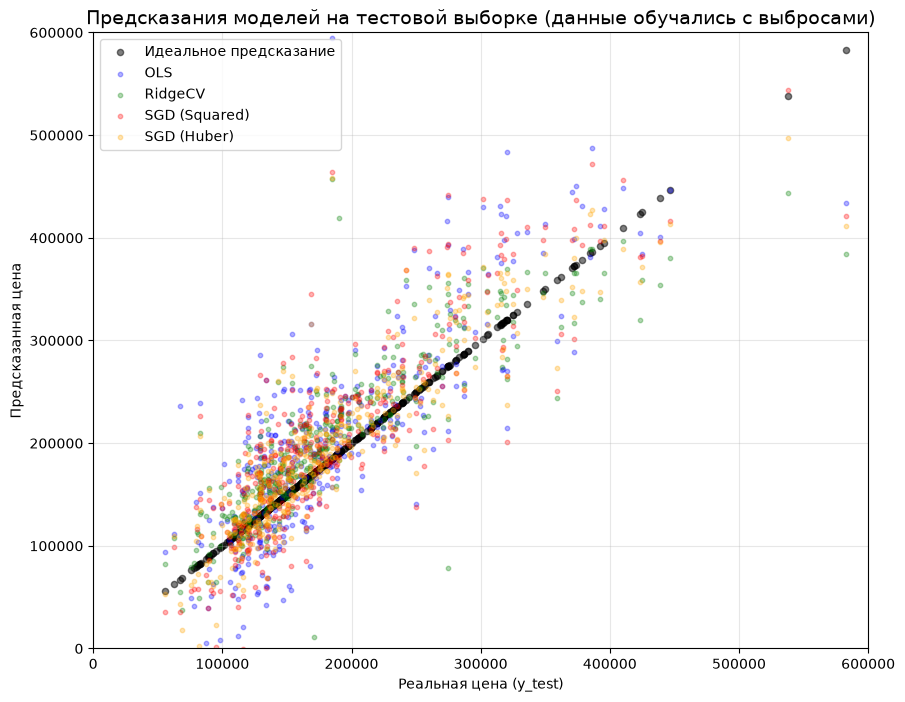

In [9]:
#код с масшатбированной переменной у.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, RidgeCV, SGDRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler

# --- 1. Создание выбросов ---
# Копируем y_train, чтобы не испортить оригинальные данные
y_train_outliers = y_train.copy()
n_outliers = int(len(y_train_outliers) * 0.05)
np.random.seed(42)
outlier_indices = np.random.choice(y_train_outliers.index, size=n_outliers, replace=False)

# Искажаем 5% данных (умножаем на 3)
y_train_outliers.loc[outlier_indices] = y_train_outliers.loc[outlier_indices] * 3

# --- 2. Масштабирование Y (КРИТИЧЕСКИ ВАЖНО для SGD) ---
# SGD не может работать с ценами в сотнях тысяч. Приводим y к среднему 0 и std 1.
scaler_y = StandardScaler()
y_train_scaled = scaler_y.fit_transform(y_train_outliers.values.reshape(-1, 1)).ravel()
y_test_scaled = scaler_y.transform(y_test.values.reshape(-1, 1)).ravel()

# --- 3. Инициализация моделей ---
# OLS и Ridge обучаем на исходном y
ols = LinearRegression()
ridge = RidgeCV(alphas=np.logspace(-3, 3, 20))

# SGD обучаем на масштабированном y.
# eta0=0.001 (уменьшили шаг), чтобы градиент не "взрывался" на выбросах.
sgd_sq = SGDRegressor(loss='squared_error', penalty=None, max_iter=5000, tol=1e-4, eta0=0.001, random_state=42)
sgd_hub = SGDRegressor(loss='huber', epsilon=1.35, penalty=None, max_iter=5000, tol=1e-4, eta0=0.001, random_state=42)

models = {
    'OLS': ols,
    'RidgeCV': ridge,
    'SGD (Squared)': sgd_sq,
    'SGD (Huber)': sgd_hub
}

results = []

# --- 4. Обучение и оценка ---
print("Обучение моделей...")
for name, model in models.items():
    if name.startswith('SGD'):
        # Обучаем на масштабированном y
        model.fit(X_train_scaled, y_train_scaled)
        # Предсказываем и возвращаем в исходный масштаб
        y_pred = scaler_y.inverse_transform(model.predict(X_test_scaled).reshape(-1, 1)).ravel()
    else:
        # Обычные модели обучаем на исходном y
        model.fit(X_train_scaled, y_train_outliers)
        y_pred = model.predict(X_test_scaled)
    
    # Считаем метрики
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    
    results.append({
        'Модель': name,
        'RMSE': rmse,
        'MAE': mae,
        'Предсказания': y_pred # Сохраняем для графиков
    })

df_results = pd.DataFrame(results)
print("\nРезультаты:")
print(df_results[['Модель', 'RMSE', 'MAE']].to_string(index=False))

# --- 5. Визуализация ---

# График 1: Столбчатая диаграмма сравнения метрик
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

# Сравнение RMSE
bars1 = ax[0].bar(df_results['Модель'], df_results['RMSE'], color=['#1f77b4', '#2ca02c', '#d62728', '#ff7f0e'])
ax[0].set_title('Сравнение RMSE (меньше = лучше)', fontsize=14)
ax[0].set_ylabel('RMSE')
ax[0].tick_params(axis='x', rotation=15)
# Добавляем значения над столбцами
for bar in bars1:
    yval = bar.get_height()
    ax[0].text(bar.get_x() + bar.get_width()/2, yval, f'{yval:,.0f}', ha='center', va='bottom', fontsize=10)

# Сравнение MAE
bars2 = ax[1].bar(df_results['Модель'], df_results['MAE'], color=['#1f77b4', '#2ca02c', '#d62728', '#ff7f0e'])
ax[1].set_title('Сравнение MAE (меньше = лучше)', fontsize=14)
ax[1].set_ylabel('MAE')
ax[1].tick_params(axis='x', rotation=15)
for bar in bars2:
    yval = bar.get_height()
    ax[1].text(bar.get_x() + bar.get_width()/2, yval, f'{yval:,.0f}', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

# График 2: Сравнение предсказаний (Scatter Plot)
# Идеальная модель должна лежать на линии y=x
plt.figure(figsize=(10, 8))
plt.scatter(y_test, y_test, color='black', alpha=0.5, label='Идеальное предсказание', s=20)

colors = {'OLS': 'blue', 'RidgeCV': 'green', 'SGD (Squared)': 'red', 'SGD (Huber)': 'orange'}
for idx, row in df_results.iterrows():
    plt.scatter(y_test, row['Предсказания'], color=colors[row['Модель']], alpha=0.3, label=row['Модель'], s=10)

plt.title('Предсказания моделей на тестовой выборке (данные обучались с выбросами)', fontsize=14)
plt.xlabel('Реальная цена (y_test)')
plt.ylabel('Предсказанная цена')
plt.legend()
plt.grid(True, alpha=0.3)

# Ограничим оси, чтобы график не растягивался из-за единичных огромных предсказаний
plt.xlim(0, 600000)
plt.ylim(0, 600000)

plt.show()